<center><h1>Velasco_Djovan_HW4</h1></center>
<br>
<br>

Name: Djovan Velasco
<br>
Github Username: Djovan-Velasco
<br>
USC ID: 8082620160

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os
from sklearn.model_selection import StratifiedKFold
from sklearn.feature_selection import RFECV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_curve, auc, accuracy_score, roc_auc_score
import statsmodels.api as sm
from sklearn.utils import resample
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegressionCV
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.model_selection import KFold


Get the AReM Data Set

In [2]:
data_path = '/Users/djovanvelasco/552_Hw4/Data/AReM'

train_files = []
test_files = []

for activity_folder in os.listdir(data_path):
    folder_path = os.path.join(data_path, activity_folder)
    
    if not os.path.isdir(folder_path):
        continue
        
    files = [f for f in os.listdir(folder_path) if f.endswith('.csv')]
    
    for file in files:
        file_path = os.path.join(folder_path, file)
        
        if activity_folder in ['bending1', 'bending2']:
            if file in ['dataset1.csv', 'dataset2.csv']:
                test_files.append((activity_folder, file_path))
            else:
                train_files.append((activity_folder, file_path))
                
        else:
            if file in ['dataset1.csv', 'dataset2.csv', 'dataset3.csv']:
                test_files.append((activity_folder, file_path))
            else:
                train_files.append((activity_folder, file_path))

### (b) Splitting Data

In [3]:
def load_instance(file_path):
    df = pd.read_csv(
        file_path, 
        skiprows=4,
        usecols=range(1, 7),
        sep=r'[,\s]+',     
        engine='python',    
        on_bad_lines='skip'  
    )
    return df.apply(pd.to_numeric, errors='coerce').dropna()

train_x = []
train_y = []

for activity, file_path in train_files:
    df = load_instance(file_path)
    train_x.append(df)
    train_y.append(activity)

test_x = []
test_y = []

for activity, file_path in test_files:
    df = load_instance(file_path)
    test_x.append(df)
    test_y.append(activity)

### (c) Feature Extraction

In [4]:
X_all = train_x + test_x 

features = []
metrics = ['min', 'max', 'mean', 'median', 'std', '1st_quart', '3rd_quart']
col_names = []

for i in range(1, 7):
    for m in metrics:
        col_names.append(f"{m}{i}")

for df in X_all:
    row = []
    
    for col in df.columns:
        metrics = [
            df[col].min(),
            df[col].max(),
            df[col].mean(),
            df[col].median(),
            df[col].std(),
            df[col].quantile(0.25),
            df[col].quantile(0.75)
        ]
        row.extend(metrics)
        
    features.append(row)

feature_df = pd.DataFrame(features, columns=col_names)

## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

In [5]:
train_y_bin = np.array([1 if 'bending' in y else 0 for y in train_y])
test_y_bin = np.array([1 if 'bending' in y else 0 for y in test_y])
def extract_features(df, l_splits):
    split_size = len(df) // l_splits
    instance_features = []
    
    for i in range(l_splits):
        start_idx = i * split_size
        end_idx = start_idx + split_size
        chunk = df.iloc[start_idx:end_idx]
        
        for col in chunk.columns:
            features = [
                chunk[col].mean(),
                chunk[col].std(),
                chunk[col].min()
            ]
            instance_features.extend(features)
            
    return instance_features

def build_feature_matrix(list_x, l_splits):
    new_features = []
    for df in list_x:
        row = extract_features(df, l_splits)
        new_features.append(row)
    return pd.DataFrame(new_features)

def plots(list_x, y_bin, l_splits, title):
    df_features = build_feature_matrix(list_x, l_splits)
    cols_to_plot = []
    feature_names = []
    for i in range(l_splits):
        offset = i * 18
        cols_to_plot.extend([
            offset + 0, offset + 1, offset + 2,    
            offset + 3, offset + 4, offset + 5,    
            offset + 15, offset + 16, offset + 17 
        ])
        suffix = f" (Part {i+1})" if l_splits > 1 else ""
        feature_names.extend([
            f"TS1 Mean{suffix}", f"TS1 Std{suffix}", f"TS1 Min{suffix}",
            f"TS2 Mean{suffix}", f"TS2 Std{suffix}", f"TS2 Min{suffix}",
            f"TS6 Mean{suffix}", f"TS6 Std{suffix}", f"TS6 Min{suffix}"
        ])

    plot_df = df_features.iloc[:, cols_to_plot].copy()
    plot_df.columns = feature_names
    plot_df['Class'] = ['Bending' if y == 1 else 'Other' for y in y_bin]
    sns.pairplot(plot_df, hue='Class', diag_kind='kde')
    plt.suptitle(title, y=1)
    plt.show()


#### i. Plots

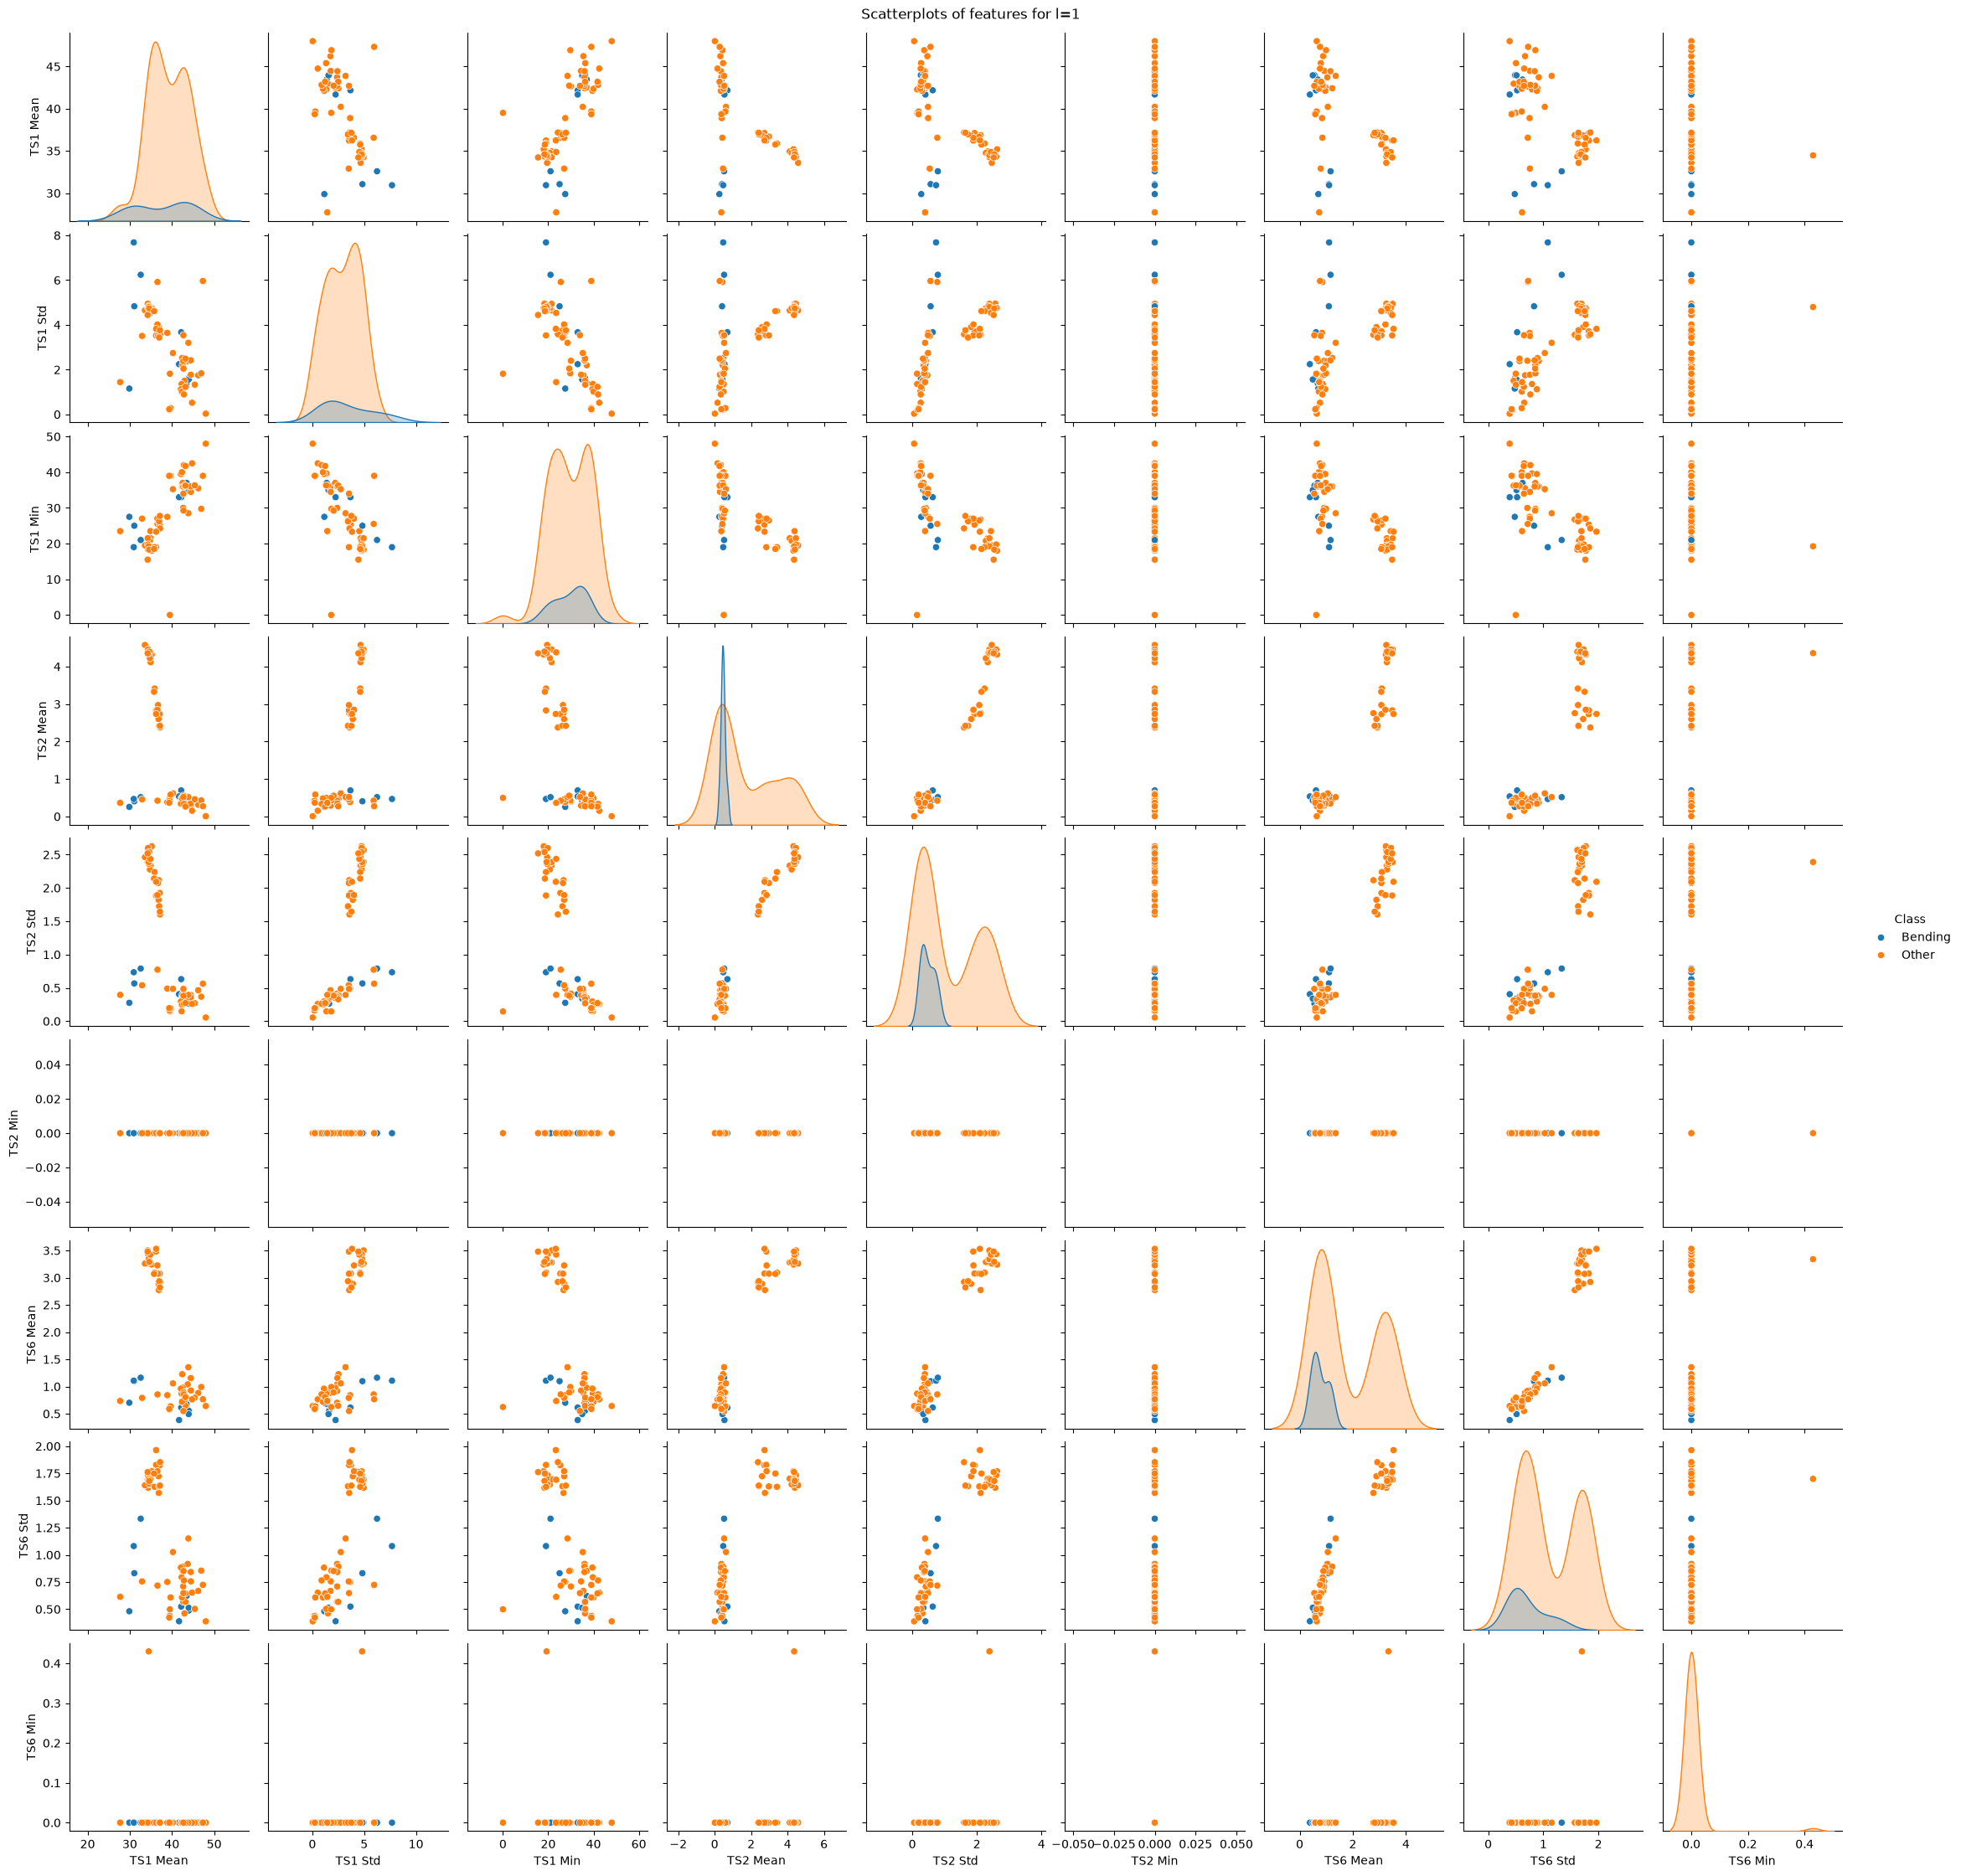

In [6]:
plots(train_x, train_y_bin, l_splits=1, title="Scatterplots of features for l=1")


#### ii. Splitted Plots

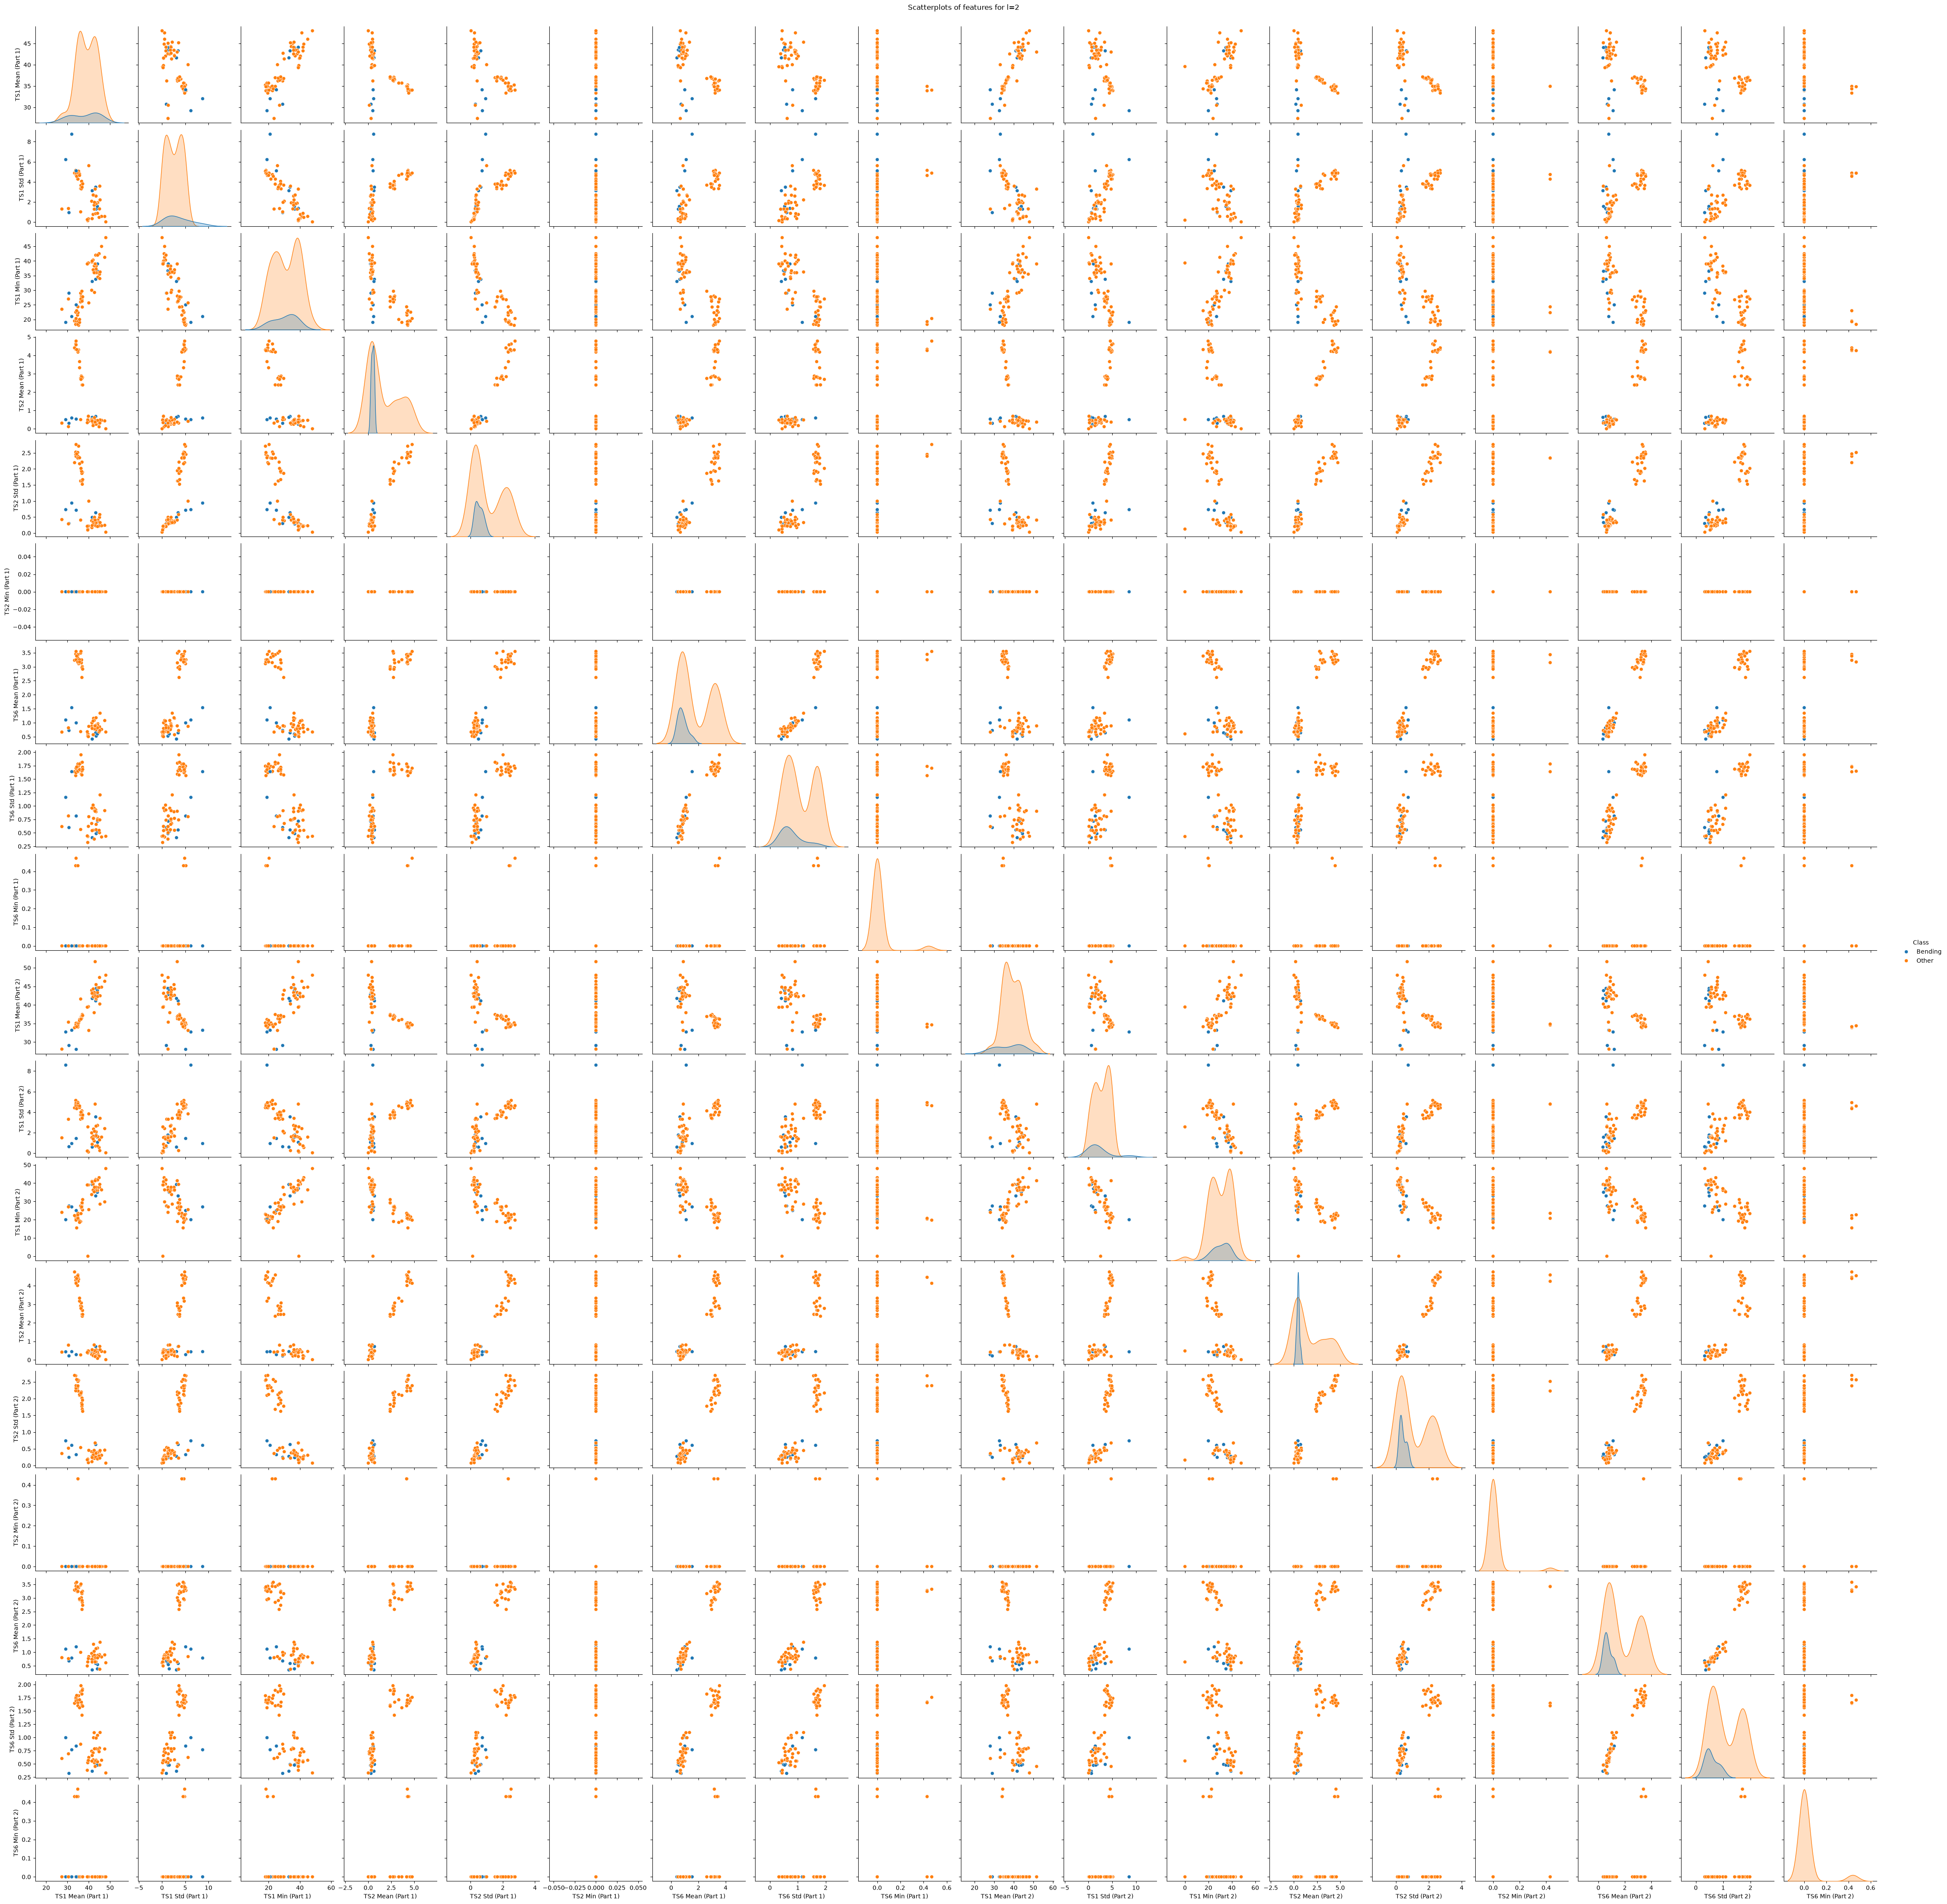

In [7]:
plots(train_x, train_y_bin, l_splits=2, title="Scatterplots of features for l=2")

The additional split with l=2 in part 2a.ii does not yield any considerable improvements in classicification. looking at the density plots we can see that for our part 2 values the majority of the blue curves (bending) lie within the orange curve. This algoritm alone is unable to separate the classes. This verifies the need for logistic regression to test higher degree splits and uncover an underlying split that the 2d plots aren't able to alone.

#### iii. Time Series Segments

In [8]:
best_l = 1
best_score = 0
best_model = None
best_features_idx = None
best_train_x = None

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)

for l in range(1, 21):
    train_x_l = build_feature_matrix(train_x, l)
    
    estimator = LogisticRegression(max_iter=10000, solver='liblinear') 
    
    selector = RFECV(estimator, step=1, cv=cv, scoring='accuracy')
    selector.fit(train_x_l, train_y_bin)
    
    score = selector.cv_results_['mean_test_score'].max()
    
    if score > best_score:
        best_score = score
        best_l = l
        best_model = selector.estimator_
        best_features_idx = selector.support_
        best_X_train = train_x_l.loc[:, best_features_idx]

print(f"Optimal number of splits (l): {best_l}")
print(f"Optimal number of features (p): {sum(best_features_idx)}")
print(f"Best CV Accuracy: {best_score:.4f}")

train_x_sm = sm.add_constant(best_X_train)
X_train_sm = sm.add_constant(best_X_train)
try:
    logit_model = sm.Logit(train_y_bin, X_train_sm).fit(disp=0, maxiter=3)
    print("\nLogistic Regression Summary (p-values & coefficients):")
    print(logit_model.summary())
except Exception as e:
    print(f"\nStatsmodels Logit failed: {e}")



Optimal number of splits (l): 18
Optimal number of features (p): 5
Best CV Accuracy: 1.0000

Logistic Regression Summary (p-values & coefficients):
                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                   69
Model:                          Logit   Df Residuals:                       63
Method:                           MLE   Df Model:                            5
Date:                Sun, 18 Oct 2026   Pseudo R-squ.:                  0.8809
Time:                        20:54:15   Log-Likelihood:                -3.1822
converged:                      False   LL-Null:                       -26.718
Covariance Type:            nonrobust   LLR p-value:                 5.496e-09
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -1.9647      6.383     -0.308      0.758     -14

/opt/homebrew/Caskroom/miniconda/base/envs/552_hw0/lib/python3.12/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


The cross-validation process determined that dividing the time series into 18 chunks was. Out of all the features extracted across those 18 chunks, recursive feature elimination identified a pruned subset of just 5 features that maximize predictive power (l=18, p =5). The cross-validation accuracy of 1.00 indicates that the "bending" and "other" classes are linearly separable using these 5 features. 

Right vs Wrong CV:

Feature selection must be performed inside the cross-validation loop. When the data is split into 5 folds, the algorithm eliminates features using only the 4 training folds, and then tests the accuracy of those features on the 1 remaining fold. This ensures the model is completely blind to the validation data when deciding which features are important. The wrong approach is to perform feature selection on the entire training dataset first to find the top 5 features, and then run 5-fold cross-validation on that pruned dataset. This causes the model to overfit because the validation folds already influenced which features were selected in the first place.

#### iv. Confusion Matrix

[[60  0]
 [ 0  9]]
1.0


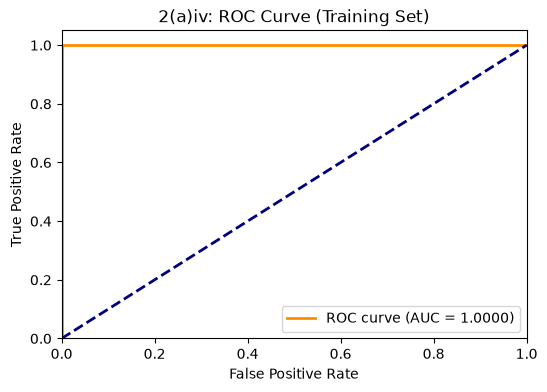

In [9]:
train_y_pred = best_model.predict(best_X_train)
train_conf_matrix = confusion_matrix(train_y_bin, train_y_pred)

print(train_conf_matrix)

y_train_prob = best_model.predict_proba(best_X_train)[:, 1]
fpr, tpr, thresholds = roc_curve(train_y_bin, y_train_prob)
roc_auc = auc(fpr, tpr)

print(roc_auc)

plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('2(a)iv: ROC Curve (Training Set)')
plt.legend(loc="lower right")
plt.show()

#### v. Test Classifier

In [10]:
test_x_l = build_feature_matrix(test_x, best_l)

test_x_l = test_x_l.fillna(0)

X_test_opt = test_x_l.loc[:, best_features_idx]

y_test_pred = best_model.predict(X_test_opt)

test_accuracy = accuracy_score(test_y_bin, y_test_pred)
test_conf_matrix = confusion_matrix(test_y_bin, y_test_pred)


print(best_score)
print(round(test_accuracy, 4))

print(test_conf_matrix)

1.0
0.9474
[[15  0]
 [ 1  3]]


The testing accuracy is slighly lower as expected. 

#### vi. Separation

Yes, the classes are well-separated to the point of causing parameter instability. Since the features extracted across the optimal 18 splits create a perfect linear boundary by separating the "bending" instances from the "other" activities, the cross-validation achieves a perfect accuracy score. As a result, the statsmodels MLE breaks down as it attempts to push the coefficients toward infinity and inflates the standard errors. As reccomended we apply a max_iter parameter which forces the algorithm to stop immaturely.

#### vii. Imbalance

Yes, there does appear to be class imbalance from our confusion matrix. Since the majority of the data sensor readings were classsified as "other" movement, we see this reflected in the matrices. "Bending" movements only account for a small proportion 9/69 in the training, and 3/16 in the testing. 

[[60  0]
 [ 0 60]]
1.0


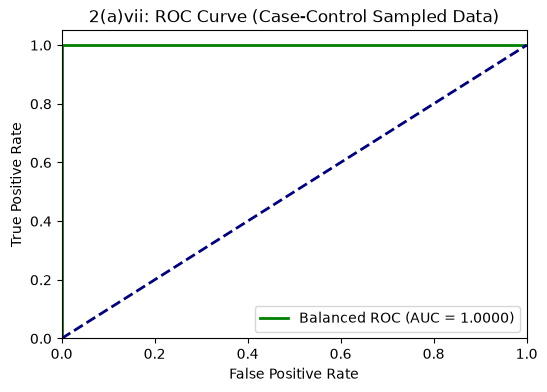

In [11]:
train_df = pd.concat([best_X_train.reset_index(drop=True), 
                      pd.Series(train_y_bin, name='target')], axis=1)

majority = train_df[train_df.target == 0]
minority = train_df[train_df.target == 1]

minority_upsampled = resample(minority, 
                              replace=True, 
                              n_samples=len(majority), 
                              random_state=123)

upsampled_df = pd.concat([majority, minority_upsampled])

train_x_bal = upsampled_df.drop('target', axis=1)
train_y_bal = upsampled_df['target']

model_bal = LogisticRegression(max_iter=10000, solver='liblinear')
model_bal.fit(train_x_bal, train_y_bal)

pred_y_bal = model_bal.predict(train_x_bal)
prob_y_bal = model_bal.predict_proba(train_x_bal)[:, 1]

bal_conf_matrix = confusion_matrix(train_y_bal, pred_y_bal)
fpr_bal, tpr_bal, _ = roc_curve(train_y_bal, prob_y_bal)
roc_auc_bal = auc(fpr_bal, tpr_bal)

print(bal_conf_matrix)
print(roc_auc_bal)

plt.figure(figsize=(6, 4))
plt.plot(fpr_bal, tpr_bal, color='green', lw=2, label=f'Balanced ROC (AUC = {roc_auc_bal:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('2(a)vii: ROC Curve (Case-Control Sampled Data)')
plt.legend(loc="lower right")
plt.show()

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [12]:
best_l_l1 = 1
best_score_l1 = 0
best_model_l1 = None
best_scaler_l1 = None

cv_l1 = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)

for l in range(1, 21):
    train_x_l1 = build_feature_matrix(train_x, l).fillna(0)
    
    scaler = StandardScaler()
    train_x_scaled = scaler.fit_transform(train_x_l1)
    
    l1_model = LogisticRegressionCV(
        Cs=10, 
        cv=cv_l1, 
        l1_ratios=[1.0],               
        solver='saga',                
        scoring='accuracy',
        max_iter=10000,
        random_state=123,
        use_legacy_attributes=False    
    )
    
    l1_model.fit(train_x_scaled, train_y_bin)
    
    score = l1_model.scores_[1].mean(axis=0).max()
    
    if score > best_score_l1:
        best_score_l1 = score
        best_l_l1 = l
        best_model_l1 = l1_model
        best_scaler_l1 = scaler

print(f"Optimal number of splits (l): {best_l_l1}")
print(f"Optimal C: {best_model_l1.C_:.4f}")
print(f"Best CV Accuracy: {best_score_l1:.4f}")

test_x_l1 = build_feature_matrix(test_x, best_l_l1).fillna(0)
test_x_scaled_l1 = best_scaler_l1.transform(test_x_l1)
y_test_pred_l1 = best_model_l1.predict(test_x_scaled_l1)

print(round(accuracy_score(test_y_bin, y_test_pred_l1), 4))
print(confusion_matrix(test_y_bin, y_test_pred_l1))

Optimal number of splits (l): 1
Optimal C: 2.7826
Best CV Accuracy: 1.0000
1.0
[[15  0]
 [ 0  4]]


#### ii. Comparison

Based on testing accuracy, the L1 penalized model performs better. Because of built in regularization of the L1 algorithm, it better handles the linear seperability issues of the unpenalized model. The L1 is also easier to implement since you only need one function to handle cross-validation, regularization, and feature pruning. 

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

In [13]:
le = LabelEncoder()
train_y_multi = le.fit_transform(train_y)
test_y_multi = le.transform(test_y)

best_l_multi = 1
best_score_multi = 0
best_model_multi = None
best_scaler_multi = None

cv_multi = KFold(n_splits=5, shuffle=True, random_state=123)

for l in range(1, 21):
    train_x_l1_m = build_feature_matrix(train_x, l).fillna(0)
    scaler = StandardScaler()
    train_x_scaled_multi = scaler.fit_transform(train_x_l1_m)
    
    multi_model = LogisticRegressionCV(
        Cs=10, 
        cv=cv_multi, 
        l1_ratios=[1.0],               
        solver='saga', 
        scoring='accuracy',            
        max_iter=10000,                 
        n_jobs=-1,
        random_state=123,
        use_legacy_attributes=False    
    )
    multi_model.fit(train_x_scaled_multi, train_y_multi)
    
    score = multi_model.scores_.mean(axis=0).max()
    
    if score > best_score_multi:
        best_score_multi = score
        best_l_multi = l
        best_model_multi = multi_model
        best_scaler_multi = scaler

print(f"\nOptimal l for Multinomial: {best_l_multi}")
print(f"Optimal C: {best_model_multi.C_:.4f}")

test_x_multi = build_feature_matrix(test_x, best_l_multi).fillna(0)
test_x_scaled_multi = best_scaler_multi.transform(test_x_multi)
multi_pred = best_model_multi.predict(test_x_scaled_multi)
multi_prob = best_model_multi.predict_proba(test_x_scaled_multi)

print("Test Accuracy:", round(accuracy_score(test_y_multi, multi_pred),4))
print(confusion_matrix(test_y_multi, multi_pred))
print(round(roc_auc_score(test_y_multi, multi_prob, multi_class='ovr'),4))


Optimal l for Multinomial: 1
Optimal C: 166.8101
Test Accuracy: 0.8947
[[2 0 0 0 0 0 0]
 [0 2 0 0 0 0 0]
 [0 0 3 0 0 0 0]
 [0 0 0 3 0 0 0]
 [0 0 0 0 2 1 0]
 [0 0 0 1 0 2 0]
 [0 0 0 0 0 0 3]]
0.9792


#### ii. Naive Bayes

In [14]:
gnb = GaussianNB()
train_x_best_multi = build_feature_matrix(train_x, best_l_multi).fillna(0)
train_x_scaled_best_multi = best_scaler_multi.transform(train_x_best_multi)

gnb.fit(train_x_scaled_best_multi, train_y_multi)
gnb_pred = gnb.predict(test_x_scaled_multi)
print("Gaussian Naive Bayes Test Accuracy:", round(accuracy_score(test_y_multi, gnb_pred), 4))

minmax = MinMaxScaler()
train_x_nonnegative = minmax.fit_transform(train_x_best_multi)
test_x_nonnegative = minmax.transform(test_x_multi)

mnb = MultinomialNB()
mnb.fit(train_x_nonnegative, train_y_multi)
mnb_pred = mnb.predict(test_x_nonnegative)
print("Multinomial Naive Bayes Test Accuracy:", round(accuracy_score(test_y_multi, mnb_pred), 4))

Gaussian Naive Bayes Test Accuracy: 0.7368
Multinomial Naive Bayes Test Accuracy: 0.7368


#### ii. Comparison

The L1 penalized multinomial classification was the best with an accuracy of 0.8947, compared to the 0.7368 of the gaussian and multinomial naive bayes methods. In continuous datasets like this one, L1 is good at reducing irrelevant coefficients to zero and reducing the overall number of features we have to consider, selecting a better boundary. On the other hand, the naive bayes methods assume that all features are independent (which is not the case) which makes our predictions less strong due to multicollinearity. 

## 3. ISLR 4.8.3

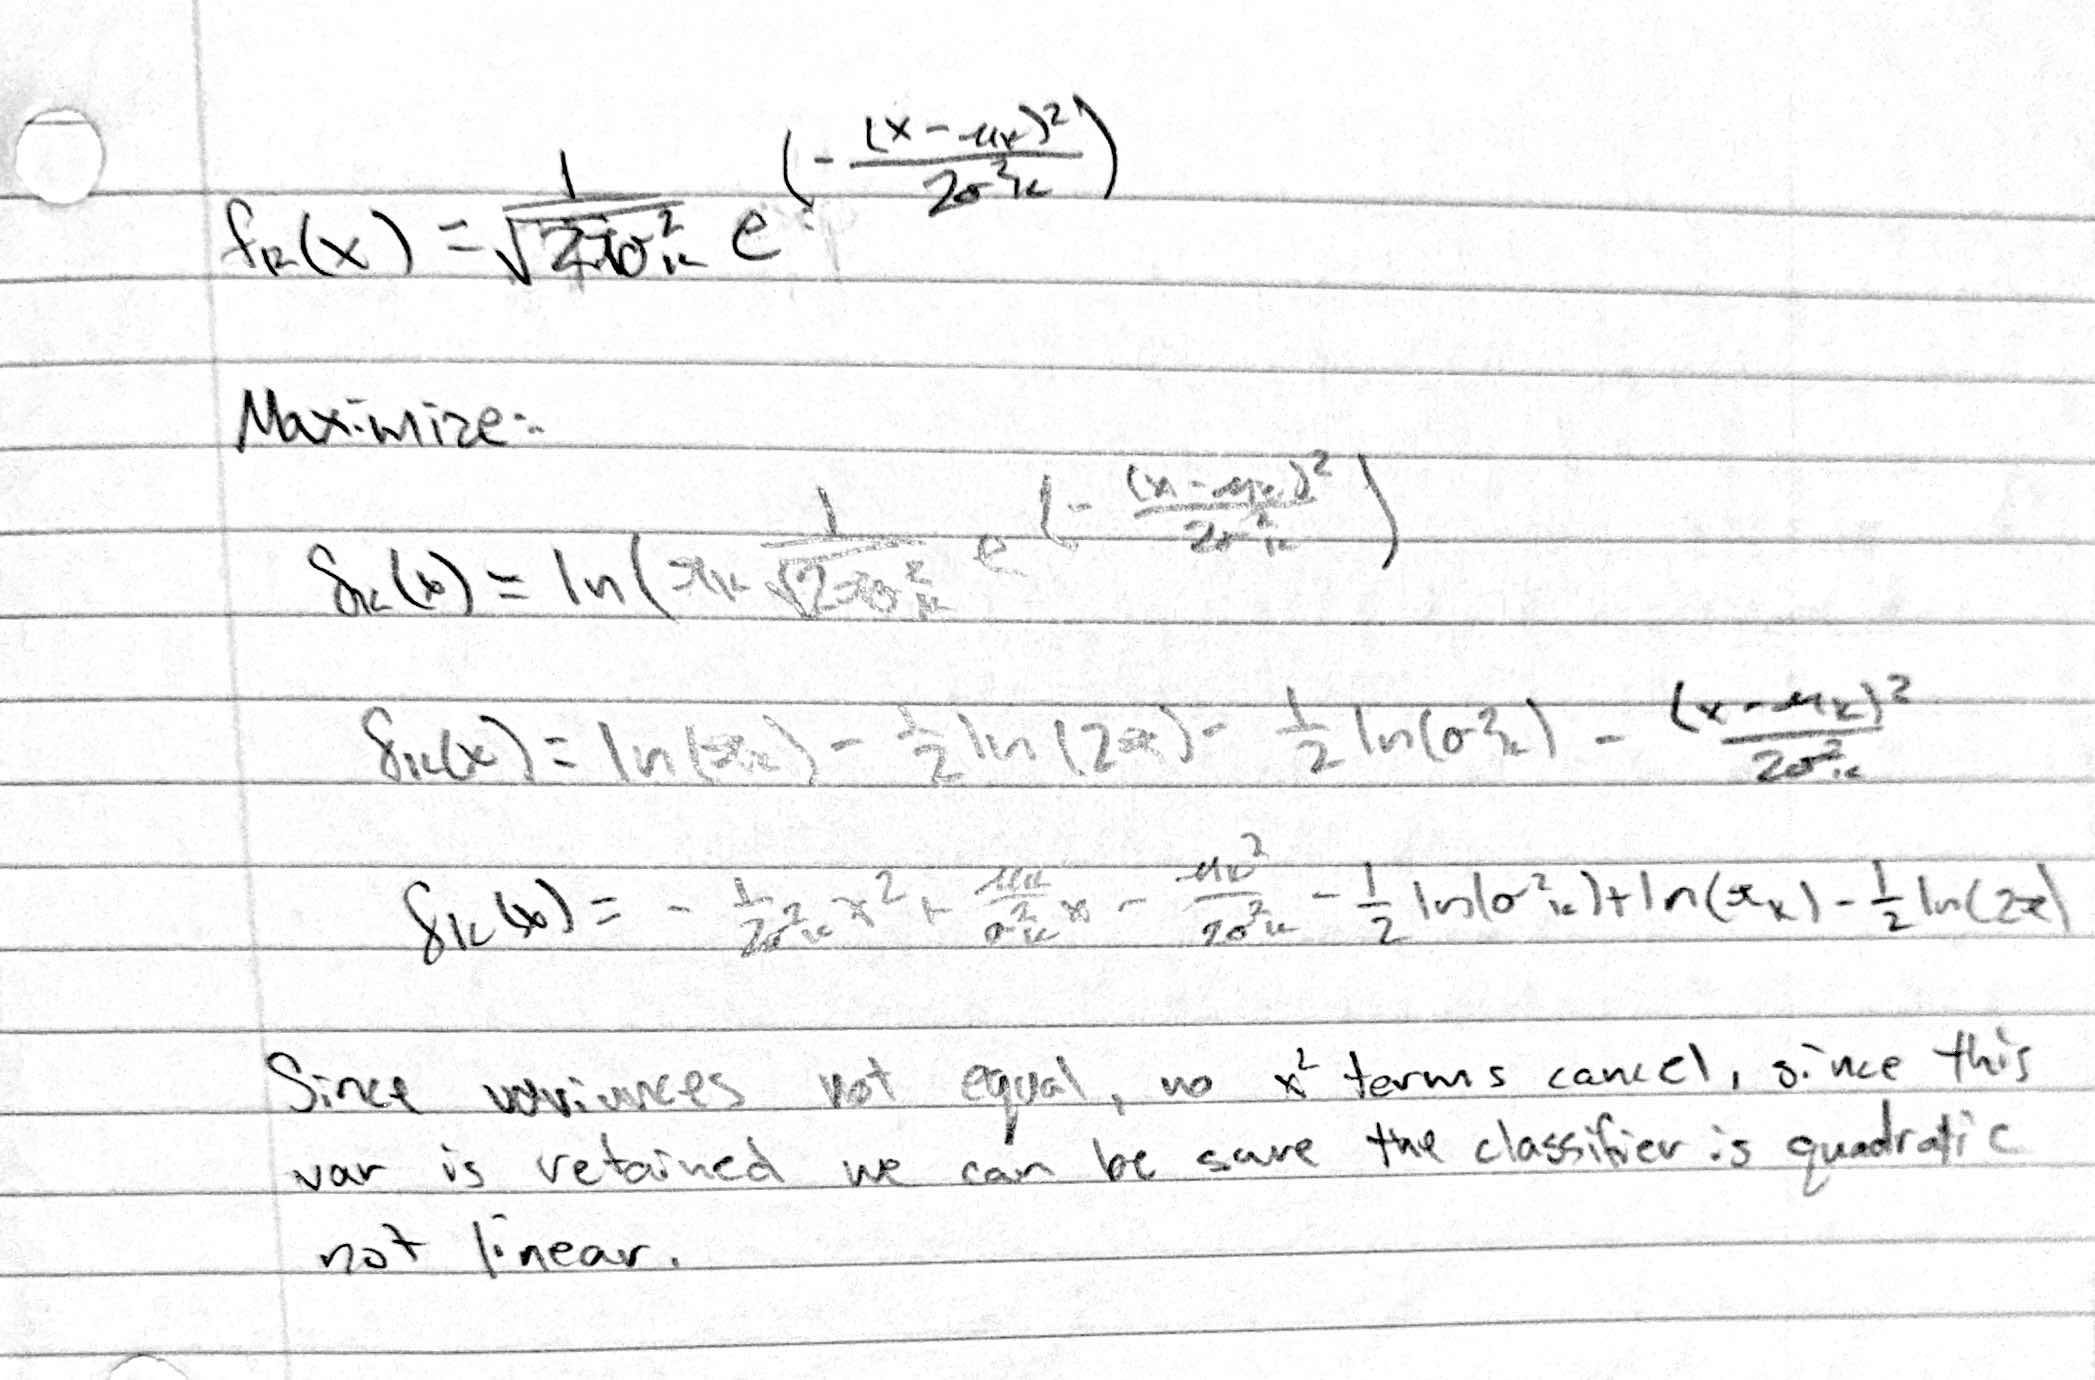

## 4. ISLR 4.8.7

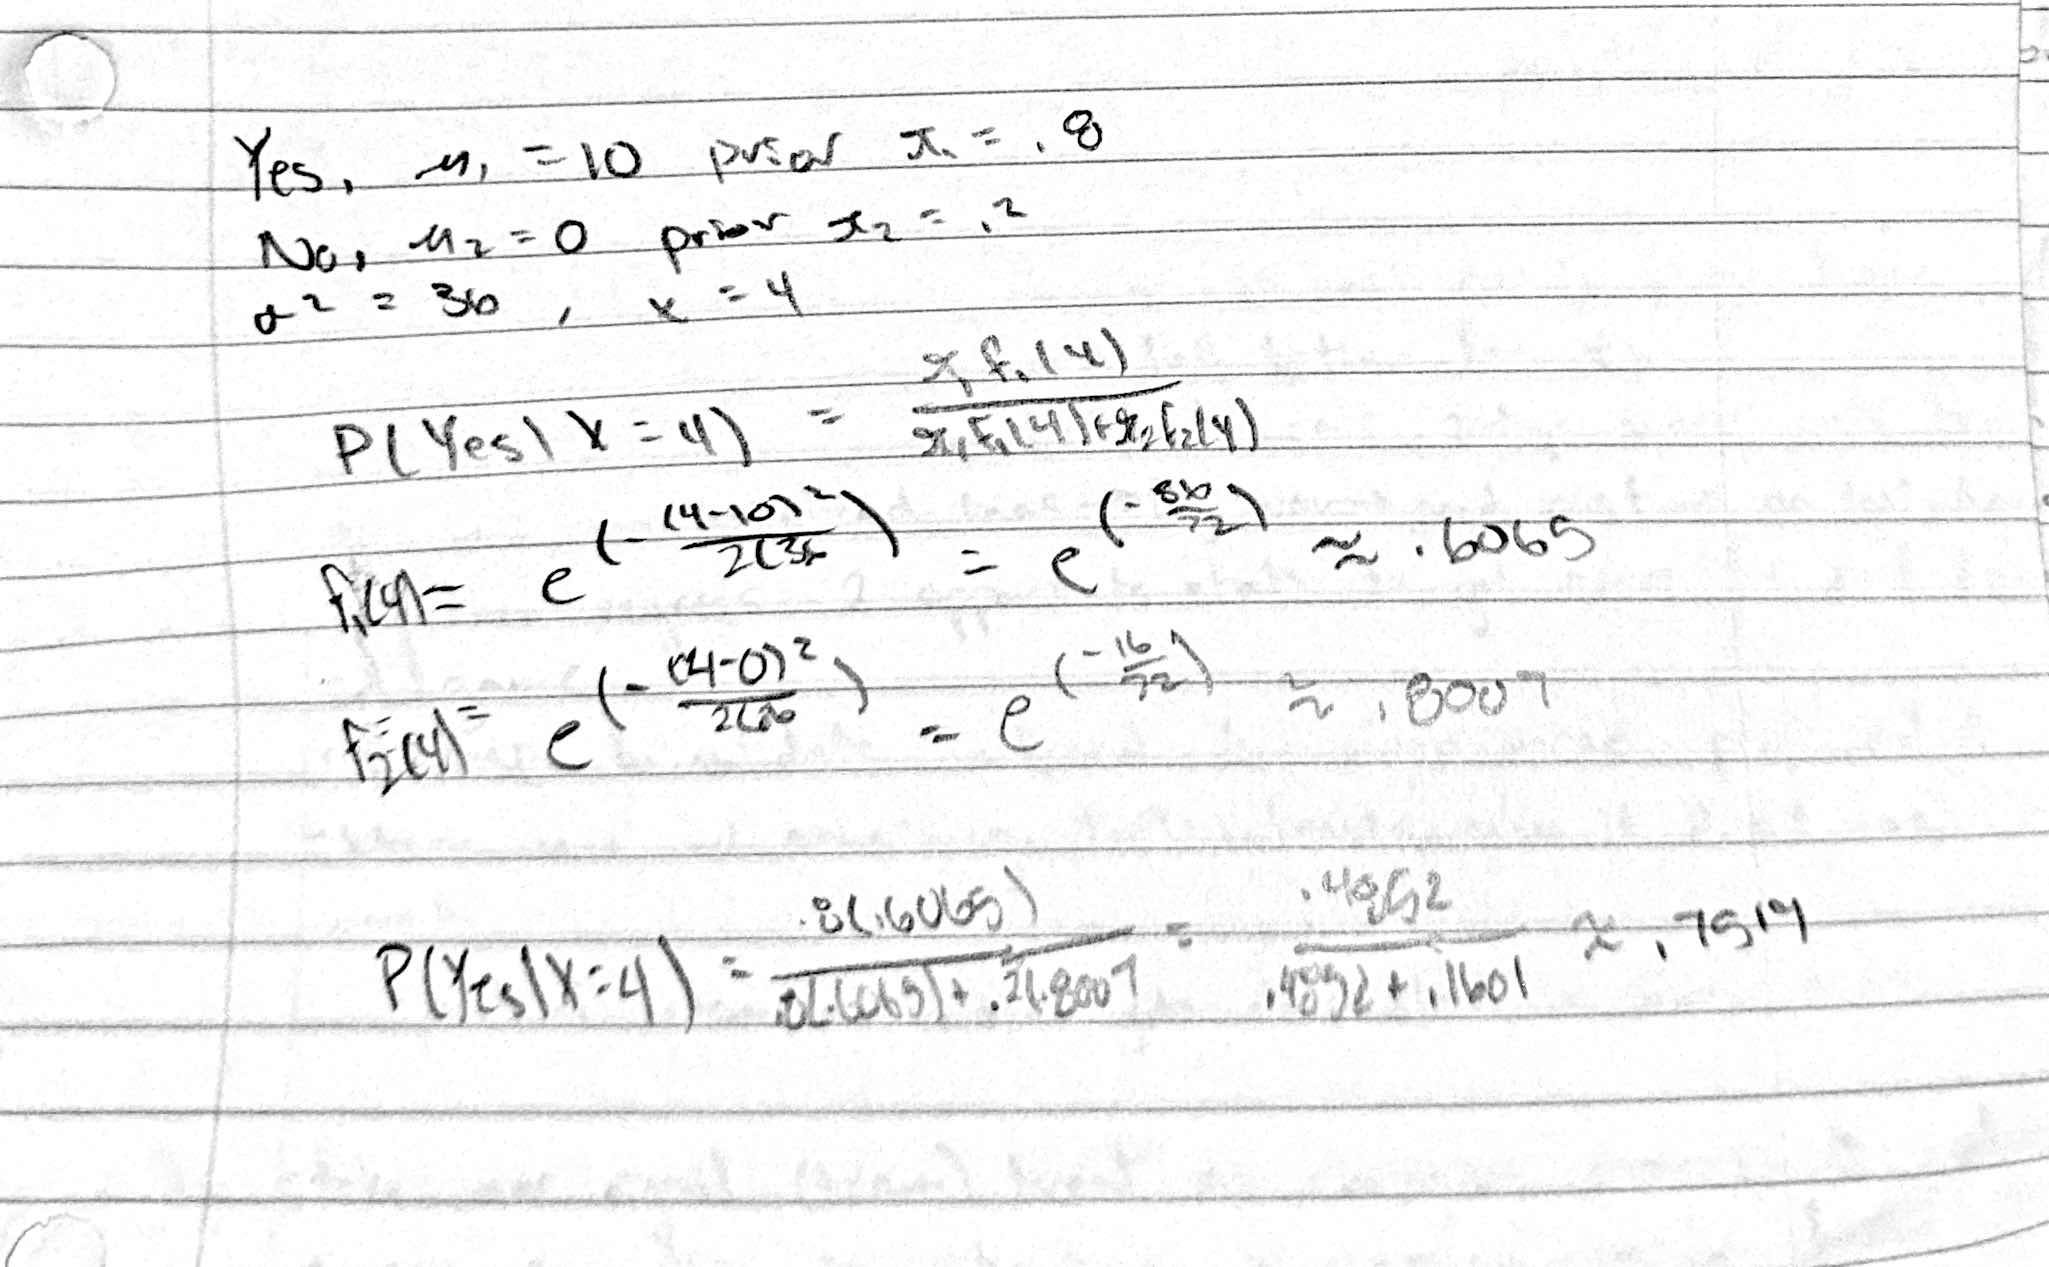

In [17]:
%cd /Users/djovanvelasco/552_Hw4
!touch README.md .gitignore requirements.txt Data/.gitkeep
!git init
!git add .
!git commit -m "Update commit"
!git branch -M main
!git remote add origin https://github.com/Djovan-Velasco/552_hw4_repo
!git push -u origin main

/Users/djovanvelasco/552_Hw4
Reinitialized existing Git repository in /Users/djovanvelasco/552_Hw4/.git/
[main 1aab257] Update commit
 1 file changed, 0 insertions(+), 0 deletions(-)
error: remote origin already exists.
Enumerating objects: 105, done.
Counting objects: 100% (105/105), done.
Delta compression using up to 10 threads
Compressing objects: 100% (104/104), done.
Writing objects: 100% (105/105), 811.93 KiB | 10.54 MiB/s, done.
Total 105 (delta 4), reused 0 (delta 0), pack-reused 0 (from 0)
remote: Resolving deltas: 100% (4/4), done.
To https://github.com/Djovan-Velasco/552_hw4_repo
 * [new branch]      main -> main
branch 'main' set up to track 'origin/main'.


In [21]:
!cd /Users/djovanvelasco/552_Hw4

!rm -rf Notebook/.git

!git rm --cached Notebook

!git add Notebook/

!git commit -m "Fix nested git repository and add notebook files"

!git push origin main

rm 'Notebook'
[main 5002674] Fix nested git repository and add notebook files
 5 files changed, 1059 insertions(+), 1 deletion(-)
 delete mode 160000 Notebook
 create mode 100644 Notebook/.gitignore
 create mode 100644 Notebook/README.md
 create mode 100644 Notebook/Velasco_Djovan_HW4.ipynb
 create mode 100644 Notebook/requirements.txt
Enumerating objects: 5, done.
Counting objects: 100% (5/5), done.
Delta compression using up to 10 threads
Compressing objects: 100% (4/4), done.
Writing objects: 100% (4/4), 2.61 MiB | 5.09 MiB/s, done.
Total 4 (delta 1), reused 0 (delta 0), pack-reused 0 (from 0)
remote: Resolving deltas: 100% (1/1), completed with 1 local object.
To https://github.com/Djovan-Velasco/552_hw4_repo
   1aab257..5002674  main -> main


In [ ]:
!git add .
!git commit -m "Update images"
!git push

[main 880de05] Update notebook
 4 files changed, 30 insertions(+), 25 deletions(-)
 rename {Work_Photos => Notebook/Work_Photos}/ISLR 4.8.3 .jpg (100%)
 rename {Work_Photos => Notebook/Work_Photos}/ISLR 4.8.7 .jpg (100%)
Enumerating objects: 9, done.
Counting objects: 100% (9/9), done.
Delta compression using up to 10 threads
Compressing objects: 100% (5/5), done.
Writing objects: 100% (5/5), 1.06 KiB | 1.06 MiB/s, done.
Total 5 (delta 3), reused 0 (delta 0), pack-reused 0 (from 0)
remote: Resolving deltas: 100% (3/3), completed with 3 local objects.
To https://github.com/Djovan-Velasco/552_hw4_repo
   5002674..880de05  main -> main
